In [ ]:
import duckdb as db
import polars as pl
import os, glob, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join("..", "..", "src"))
from cfg import DROP, STD_COLS, COUNT_COLS, SHORT, HERE, DATASET, PROCESSED, DB_PATH, load_extensions

In [ ]:
conn = db.connect(database=DB_PATH)
metrics_raw_long = conn.execute("SELECT timestamp, short_name, value FROM metrics_raw").pl()
noon_reports = conn.execute("SELECT * FROM noon_reports").pl()
jan25 = conn.execute("SELECT * FROM jan25").pl()
metrics_reg = conn.execute("SELECT * FROM metrics_registration").pl()
metrics_wide = conn.execute("SELECT * FROM metrics_wide").pl()
conn.close()

c:\AID Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


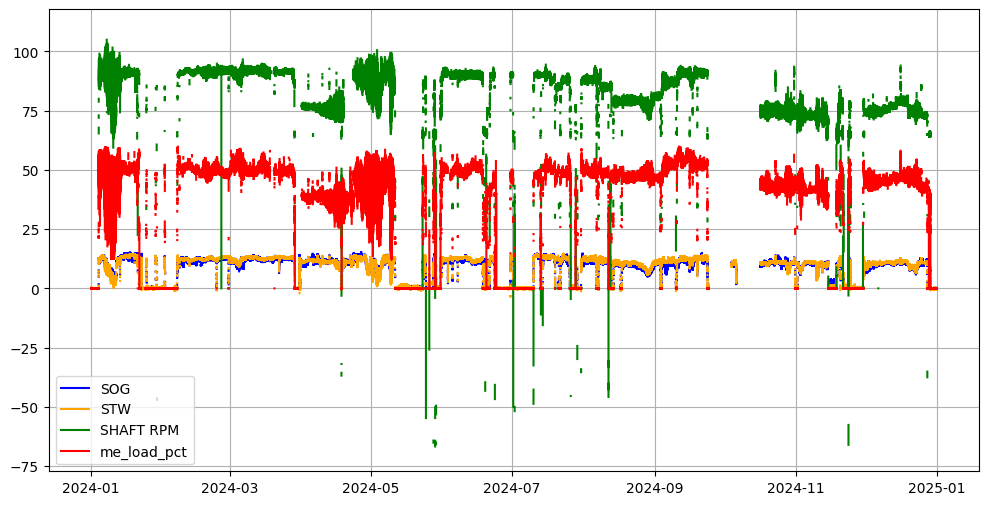

In [9]:
plt.figure(figsize=(12, 6))
plt.grid(True)
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["sog_kn"].to_numpy(), color = "blue", label = "SOG")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["stw_kn"].to_numpy(), color = "orange", label = "STW")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["me_rpm"].to_numpy(), color = "green", label = "SHAFT RPM")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["me_load_pct"].to_numpy(), color = "red", label = "me_load_pct")
plt.legend()
plt.show()

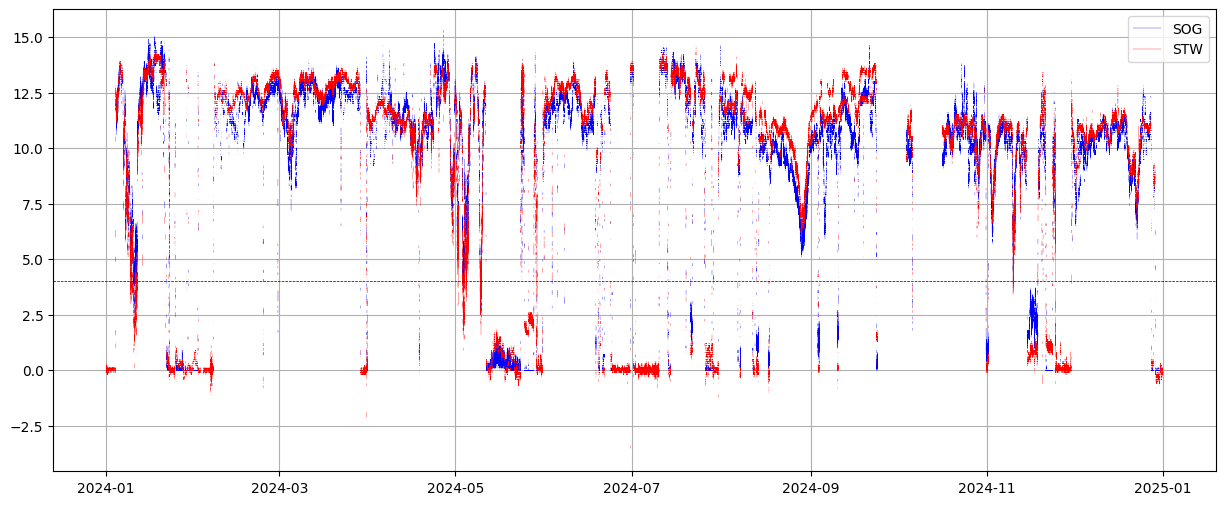

In [ ]:
plt.figure(figsize=(15, 6))
plt.grid(True)
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["sog_kn"].to_numpy(), color = "blue", label = "SOG", lw=0.25)
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["stw_kn"].to_numpy(), color = "red", label = "STW", lw=0.25)
plt.axhline(4, color = "black", ls = "--", lw = 0.5, )
ax.text(x=metrics_wide["timestamp"][0],y=4,s="4kn",color='white',fontweight='bold',va='center',ha='center',bbox=dict(facecolor='red', edgecolor='none', boxstyle='round,pad=0.3'))
plt.axhline(4, color = "black", ls = "--", lw = 0.5, )
ax.text(x=metrics_wide["timestamp"][0],y=4,s="4kn",color='white',fontweight='bold',va='center',ha='center',bbox=dict(facecolor='red', edgecolor='none', boxstyle='round,pad=0.3'))
plt.legend(loc= "upper right")
plt.show()

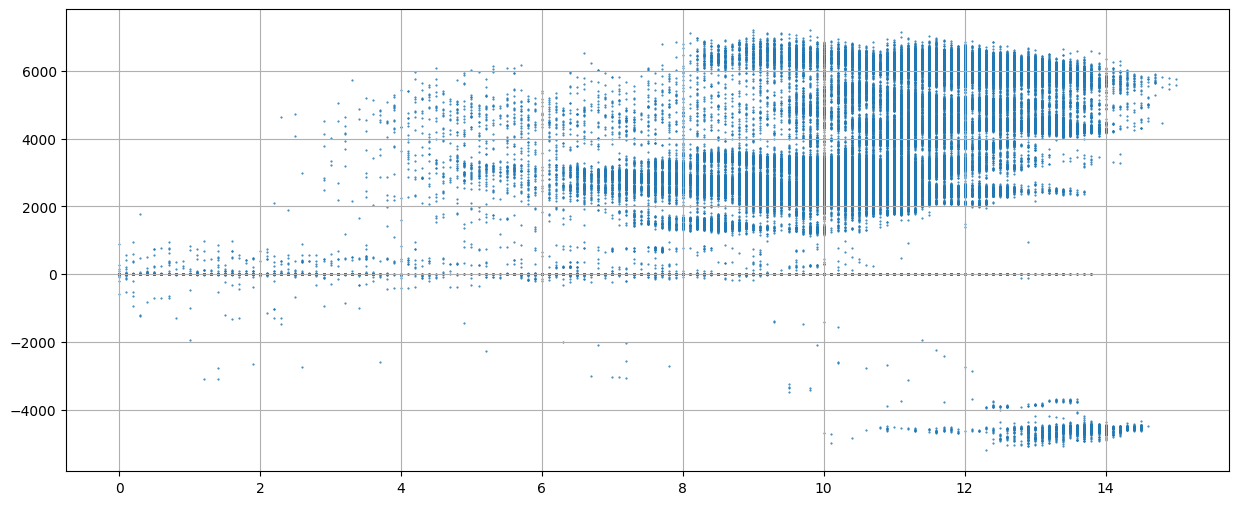

In [9]:
plt.figure(figsize=(15, 6))
plt.grid(True)
plt.scatter(metrics_wide["sog_kn"].to_numpy(),metrics_wide["shaft_kw"].to_numpy(), s= 0.25 )
plt.show()

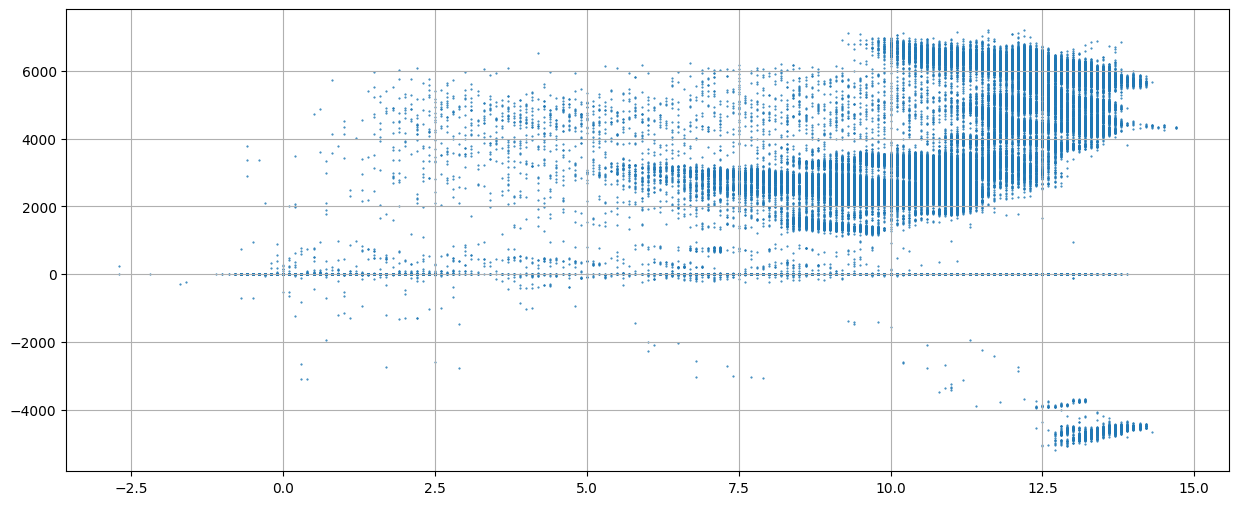

In [10]:
plt.figure(figsize=(15, 6))
plt.grid(True)
plt.scatter( metrics_wide["stw_kn"].to_numpy(),metrics_wide["shaft_kw"].to_numpy(),s = 0.25 )
plt.show()